# Entrenamiento y evaluación de un clasificador de conceptos facturas electrónicas ecuatorianas


## 1. Configuración del entorno


In [1]:
%pip install -q numpy pandas pyarrow scipy scikit-learn matplotlib threadpoolctl joblib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import unicodedata
import warnings
from pathlib import Path
from textwrap import fill

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.optimize import Bounds, LinearConstraint, milp
from scipy.sparse import eye, kron, vstack
from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.pipeline import Pipeline
from threadpoolctl import threadpool_limits

In [3]:
RANDOM_STATE = 42
C_VALUES = [0.1, 1.0, 10.0]
CLASS_WEIGHTS = [None, "balanced"]
MAX_ITERATIONS = 2000
THREAD_LIMIT = 4
PARTITION_TIME_LIMIT = 60.0

CONCEPT_KEY = "description_comparison_text"
PARTITIONS = ["train", "validation", "test"]
PARTITION_NAMES = {"train": "Entrenamiento", "validation": "Validación", "test": "Test"}

CATEGORIES = [
    "Alimentación",
    "Salud",
    "Educación, Arte y Cultura",
    "Vivienda",
    "Vestimenta",
    "Turismo Nacional",
    "Otros",
]

In [4]:
project_candidates = [
    candidate
    for parent in (Path.cwd(), *Path.cwd().parents)
    for candidate in (parent, parent / "ecuador-einvoice-classifier")
]

PROJECT_DIR = next(
    (
        path
        for path in project_candidates
        if (path / "ml/data/cleaned/model_dataset.parquet").is_file()
    ),
    None,
)

if PROJECT_DIR is None:
    raise FileNotFoundError(
        "Abre el notebook desde el proyecto o su carpeta de trabajo."
    )

In [5]:
ML_DIR = PROJECT_DIR / "ml"
MODELS_DIR = ML_DIR / "outputs/models/training"
REPORTS_DIR = ML_DIR / "outputs/reports/training"
FIGURES_DIR = ML_DIR / "outputs/figures/training"

for directory in (MODELS_DIR, REPORTS_DIR, FIGURES_DIR):
    directory.mkdir(parents=True, exist_ok=True)

dataset = pd.read_parquet(ML_DIR / "data/cleaned/model_dataset.parquet").reset_index(
    drop=True
)
category_labels = dataset["category"]

# Toal de registros por categoría
total_records_per_category = category_labels.value_counts().reindex(CATEGORIES)

print(
    f"Entrada: {len(dataset):,} conceptos de "
    f"{dataset['source_file_id'].nunique():,} facturas."
)

Entrada: 22,754 conceptos de 7,204 facturas.


In [6]:
category_tick_labels = [fill(category, width=19) for category in CATEGORIES]
category_colors = dict(
    zip(
        CATEGORIES,
        ["#287b70", "#af5369", "#8065a5", "#b18035", "#527fa7", "#44949b", "#737d8c"],
        strict=True,
    )
)

plt.rcParams.update(
    {
        "figure.dpi": 110,
        "font.size": 10,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titleweight": "bold",
        "axes.labelcolor": "#334155",
        "text.color": "#1e293b",
        "axes.edgecolor": "#cbd5e1",
        "grid.color": "#e2e8f0",
    }
)


In [7]:
def generate_and_save_figure(figure, name: str, dpi: int = 300) -> None:
    """Guarda, muestra y cierra la figura."""
    figure.savefig(FIGURES_DIR / f"{name}.png", dpi=dpi, bbox_inches="tight")
    plt.show()
    plt.close(figure)

## 2. Partición de los datos


Se realiza una partición estratificada de los datos en tres conjuntos: entrenamiento, validación y prueba, de modo que 80% de los conceptos se usarán para entrenar el modelo, 10% para ajustar hiperparámetros y 10% para evaluar su desempeño final.


In [8]:
def component_root(component_parents: np.ndarray, invoice_index: int) -> int:
    """Encuentra la raíz y comprime el camino del grupo de facturas."""
    while component_parents[invoice_index] != invoice_index:
        component_parents[invoice_index] = component_parents[
            component_parents[invoice_index]
        ]
        invoice_index = int(component_parents[invoice_index])

    return invoice_index

In [9]:
if dataset[CONCEPT_KEY].isna().any() or dataset[CONCEPT_KEY].str.strip().eq("").any():
    raise ValueError("Hay conceptos sin una clave de comparación válida.")

invoice_codes, invoice_ids = pd.factorize(dataset["source_file_id"], sort=True)
component_parents = np.arange(len(invoice_ids))

first_invoice_for_concept = {}

for invoice_code, concept in zip(invoice_codes, dataset[CONCEPT_KEY], strict=True):
    first_invoice = first_invoice_for_concept.setdefault(concept, int(invoice_code))
    current_root = component_root(component_parents, int(invoice_code))
    matching_root = component_root(component_parents, first_invoice)

    if current_root != matching_root:
        component_parents[max(current_root, matching_root)] = min(
            current_root, matching_root
        )

invoice_roots = [
    component_root(component_parents, int(invoice_code))
    for invoice_code in invoice_codes
]

dataset["concept_component"] = pd.factorize(np.asarray(invoice_roots), sort=True)[0]

records_per_component = pd.crosstab(
    dataset["concept_component"], category_labels
).reindex(columns=CATEGORIES, fill_value=0)

In [10]:
# 10 % de registros por cada categoria para validación
# 10 % de registros por cada categoria para test
# El resto será usado para el entrenamiento
holdout_records_per_category = np.rint(total_records_per_category * 0.1).astype(int)

target_records_per_partition = pd.DataFrame(
    {
        "train": total_records_per_category - 2 * holdout_records_per_category,
        "validation": holdout_records_per_category,
        "test": holdout_records_per_category,
    }
)

pattern_summary = (
    records_per_component.value_counts(sort=False)
    .rename("component_count")
    .reset_index()
    .sort_values(CATEGORIES)
    .reset_index(drop=True)
).rename_axis("pattern_id")

In [11]:
category_counts_per_pattern = pattern_summary[CATEGORIES].to_numpy(dtype=float)
components_per_pattern = pattern_summary["component_count"].to_numpy(dtype=float)
total_patterns = len(pattern_summary)
total_partitions = len(PARTITIONS)

total_assignment_variables = total_patterns * total_partitions

component_constraints = kron(
    eye(total_patterns), np.ones((1, total_partitions)), format="csc"
)

category_constraints = kron(
    category_counts_per_pattern.T, eye(total_partitions), format="csc"
)

combined_constraints = vstack(
    [component_constraints, category_constraints], format="csc"
)

required_totals = np.concatenate(
    [components_per_pattern, target_records_per_partition.to_numpy(dtype=float).ravel()]
)

In [12]:
partition_solution = milp(
    c=np.zeros(total_assignment_variables),
    integrality=np.ones(total_assignment_variables),
    bounds=Bounds(
        np.zeros(total_assignment_variables),
        np.repeat(components_per_pattern, total_partitions),
    ),
    constraints=LinearConstraint(
        combined_constraints, required_totals, required_totals
    ),
    options={"time_limit": PARTITION_TIME_LIMIT, "presolve": True},
)

if not partition_solution.success or partition_solution.x is None:
    raise RuntimeError(f"No se pudo cerrar la partición: {partition_solution.message}")

integer_assignments = np.rint(partition_solution.x).astype(int)

maximum_constraint_error = float(
    np.abs(combined_constraints @ integer_assignments - required_totals).max()
)

if maximum_constraint_error != 0 or not np.allclose(
    partition_solution.x, integer_assignments
):
    raise ValueError("La asignación no cumple las restricciones enteras.")

pattern_partition_counts = integer_assignments.reshape(total_patterns, total_partitions)

In [13]:
components_with_patterns = records_per_component.reset_index().merge(
    pattern_summary.reset_index()[["pattern_id", *CATEGORIES]],
    on=CATEGORIES,
    validate="many_to_one",
)

random_generator = np.random.default_rng(RANDOM_STATE)
component_partitions = pd.Series(index=records_per_component.index, dtype="str")

for pattern_id, pattern_components in components_with_patterns.groupby(
    "pattern_id", sort=True
):
    shuffled_components = random_generator.permutation(
        pattern_components["concept_component"].to_numpy()
    )
    partition_boundaries = np.cumsum([0, *pattern_partition_counts[pattern_id]])

    for partition_index, partition in enumerate(PARTITIONS):
        partition_start = partition_boundaries[partition_index]
        partition_end = partition_boundaries[partition_index + 1]

        assigned_components = shuffled_components[partition_start:partition_end]
        component_partitions.loc[assigned_components] = partition

dataset["partition"] = dataset["concept_component"].map(component_partitions)

if dataset["partition"].isna().any():
    raise ValueError("Quedaron conceptos sin asignación.")

partition_masks = {
    partition: dataset["partition"].eq(partition) for partition in PARTITIONS
}

training_mask = partition_masks["train"]
validation_mask = partition_masks["validation"]
test_mask = partition_masks["test"]

In [14]:
for partition in PARTITIONS:
    print(
        f"{PARTITION_NAMES[partition]}: {partition_masks[partition].sum():,} conceptos"
    )

Entrenamiento: 18,202 conceptos
Validación: 2,276 conceptos
Test: 2,276 conceptos


## 3. Entrenamiento del modelo


Se utiliza `normalized_description` como entrada para TF-IDF, considerando palabras individuales y pares consecutivos, con conversión a minúsculas y conservación de tildes, números y términos de un carácter, además de normalización L2 e IDF suavizado. El clasificador emplea regresión logística multiclase con `lbfgs` y regularización L2, evaluando seis combinaciones de `C` (0,1, 1 y 10) y pesos de clase uniformes o equilibrados, ajustadas exclusivamente con los datos de entrenamiento.

Se selecciona el modelo con mayor F1 macro de validación, utilizando los valores sin redondear y resolviendo posibles empates mediante el menor `C` y la preferencia por pesos uniformes. Finalmente, el modelo seleccionado se evalúa con el conjunto de prueba, sin volver a entrenarlo con los datos de validación o prueba.


In [15]:
descriptions = (
    dataset["normalized_description"]
    .fillna("")
    .map(lambda text: " ".join(unicodedata.normalize("NFKC", text).split()))
)

In [16]:
vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    token_pattern=r"(?u)\b\w+\b",
    lowercase=True,
    strip_accents=None,
    norm="l2",
    smooth_idf=True,
)

classifier = LogisticRegression(
    solver="lbfgs",
    l1_ratio=0.0,
    max_iter=MAX_ITERATIONS,
    tol=1e-4,
)

base_model = Pipeline(
    [
        ("tfidf", vectorizer),
        ("classifier", classifier),
    ]
)

In [17]:
candidate_models = {}
candidate_results = []

for regularization in C_VALUES:
    for class_weight in CLASS_WEIGHTS:
        candidate_model = clone(base_model).set_params(
            classifier__C=regularization,
            classifier__class_weight=class_weight,
        )

        with warnings.catch_warnings():
            warnings.simplefilter("error", ConvergenceWarning)

            with threadpool_limits(limits=THREAD_LIMIT):
                candidate_model.fit(
                    descriptions.loc[training_mask],
                    category_labels.loc[training_mask],
                )
                candidate_predictions = candidate_model.predict(
                    descriptions.loc[validation_mask]
                )

        validation_f1 = f1_score(
            category_labels.loc[validation_mask],
            candidate_predictions,
            labels=CATEGORIES,
            average="macro",
            zero_division=0,
        )
        candidate_models[(regularization, class_weight)] = candidate_model
        candidate_results.append(
            {
                "C": regularization,
                "class_weight": class_weight,
                "weight_label": "Uniformes" if class_weight is None else "Equilibrados",
                "validation_f1_macro": validation_f1,
            }
        )

In [18]:
selection_results = pd.DataFrame(candidate_results)

display(
    selection_results[["C", "weight_label", "validation_f1_macro"]]
    .rename(
        columns={
            "weight_label": "Pesos de clase",
            "validation_f1_macro": "F1 macro en validación",
        }
    )
    .round(6)
)

,C,Pesos de clase,F1 macro en validación
0,0.1,Uniformes,0.249979
1,0.1,Equilibrados,0.455085
2,1.0,Uniformes,0.464042
3,1.0,Equilibrados,0.540879
4,10.0,Uniformes,0.585008
5,10.0,Equilibrados,0.574206


In [19]:
selected_candidate = min(
    candidate_results,
    key=lambda result: (
        -result["validation_f1_macro"],
        result["C"],
        result["class_weight"] is not None,
    ),
)
model = candidate_models[(selected_candidate["C"], selected_candidate["class_weight"])]
class_order = model.classes_
class_columns = {category: index for index, category in enumerate(class_order)}

print(
    f"Modelo seleccionado: C={selected_candidate['C']}, "
    f"class_weight={selected_candidate['class_weight']} "
    f"({selected_candidate['weight_label'].lower()})."
)
print(f"F1 macro de validación: {selected_candidate['validation_f1_macro']:.6f}")
print(f"Vocabulario: {len(model.named_steps['tfidf'].vocabulary_):,} términos")
print(f"Iteraciones: {model.named_steps['classifier'].n_iter_.max()}")

Modelo seleccionado: C=10.0, class_weight=None (uniformes).
F1 macro de validación: 0.585008
Vocabulario: 26,780 términos
Iteraciones: 72


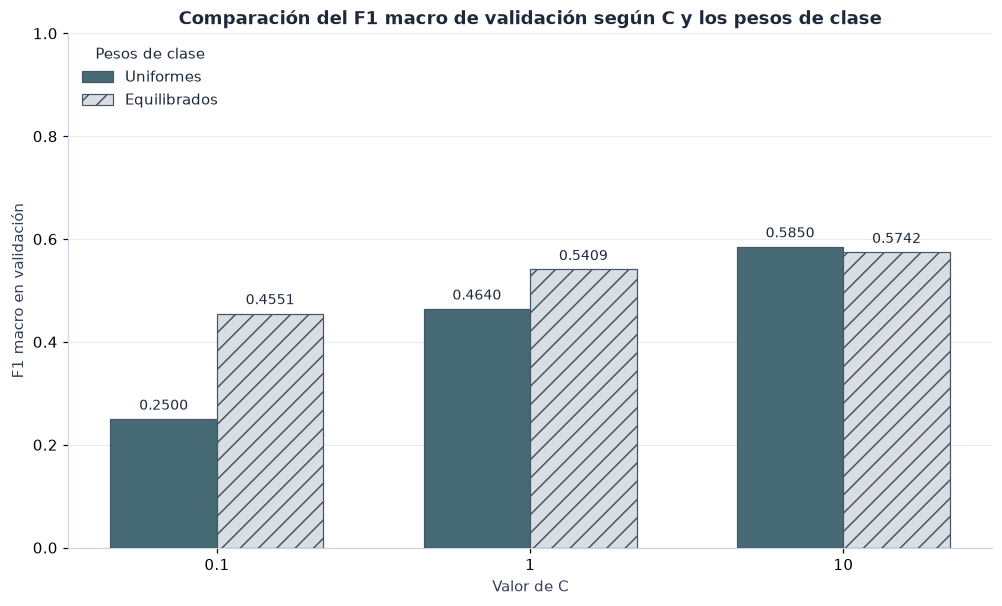

In [20]:
comparison_scores = selection_results.pivot(
    index="C", columns="weight_label", values="validation_f1_macro"
).reindex(index=C_VALUES, columns=["Uniformes", "Equilibrados"])

figure, axis = plt.subplots(figsize=(9, 5.4), layout="constrained")
positions = np.arange(len(comparison_scores))
bar_width = 0.34
bars_by_weight = {}

for offset, weight_label, color, hatch in (
    (-0.5, "Uniformes", "#466b75", None),
    (0.5, "Equilibrados", "#d9dee3", "//"),
):
    bars = axis.bar(
        positions + offset * bar_width,
        comparison_scores[weight_label],
        width=bar_width,
        label=weight_label,
        color=color,
        edgecolor="#475569",
        linewidth=0.8,
        hatch=hatch,
        zorder=3,
    )
    axis.bar_label(bars, fmt="%.4f", padding=4, fontsize=9)
    bars_by_weight[weight_label] = bars

axis.set(
    xticks=positions,
    xticklabels=[f"{value:g}" for value in comparison_scores.index],
    xlabel="Valor de C",
    ylabel="F1 macro en validación",
    ylim=(0, 1),
    title="Comparación del F1 macro de validación según C y los pesos de clase",
)
axis.set_yticks(np.linspace(0, 1, 6))
axis.set_axisbelow(True)
axis.grid(axis="y", alpha=0.8)
axis.legend(title="Pesos de clase", loc="upper left", frameon=False)

generate_and_save_figure(figure, "01_selection_validation", dpi=300)


## 4. Evaluación en validación y test


Se evalúa el clasificador mediante exactitud, precisión, recall, F1 y ROC-AUC multiclase con el enfoque uno contra el resto, utilizando promedios macro, que otorgan el mismo peso a todas las categorías, y weighted, que consideran la cantidad de conceptos de cada una.


In [21]:
with threadpool_limits(limits=THREAD_LIMIT):
    validation_predictions = model.predict(descriptions.loc[validation_mask])
    validation_probabilities = model.predict_proba(descriptions.loc[validation_mask])
    test_predictions = model.predict(descriptions.loc[test_mask])
    test_probabilities = model.predict_proba(descriptions.loc[test_mask])

evaluation_results = {
    "validation": {
        "actual": category_labels.loc[validation_mask],
        "predicted": validation_predictions,
        "probabilities": validation_probabilities,
    },
    "test": {
        "actual": category_labels.loc[test_mask],
        "predicted": test_predictions,
        "probabilities": test_probabilities,
    },
}

In [22]:
partition_metrics = []

for partition, results in evaluation_results.items():
    report = classification_report(
        results["actual"],
        results["predicted"],
        labels=CATEGORIES,
        output_dict=True,
        zero_division=0,
    )
    metrics = {
        "partition": partition,
        "support": len(results["actual"]),
        "accuracy": accuracy_score(results["actual"], results["predicted"]),
    }

    for average in ("macro", "weighted"):
        for metric, report_key in (
            ("precision", "precision"),
            ("recall", "recall"),
            ("f1", "f1-score"),
        ):
            metrics[f"{metric}_{average}"] = report[f"{average} avg"][report_key]

        metrics[f"roc_auc_ovr_{average}"] = roc_auc_score(
            results["actual"],
            results["probabilities"],
            labels=class_order,
            multi_class="ovr",
            average=average,
        )

    partition_metrics.append(metrics)

metrics_by_partition = pd.DataFrame(partition_metrics).set_index("partition")

display(metrics_by_partition.round(4))

,support,accuracy,precision_macro,recall_macro,f1_macro,roc_auc_ovr_macro,precision_weighted,recall_weighted,f1_weighted,roc_auc_ovr_weighted
partition,,,,,,,,,,
validation,2276,0.7873,0.7713,0.5328,0.5850,0.9220,0.8108,0.7873,0.7726,0.9322
test,2276,0.7056,0.7763,0.5569,0.6219,0.9223,0.7413,0.7056,0.7034,0.8917


### 4.1. Métricas por categoría


In [23]:
print(" === VALIDACIÓN ===")

print(
    classification_report(
        category_labels.loc[validation_mask],
        validation_predictions,
        labels=CATEGORIES,
        target_names=CATEGORIES,
        digits=4,
        zero_division=0,
    )
)

 === VALIDACIÓN ===
                           precision    recall  f1-score   support

             Alimentación     0.9075    0.8390    0.8719       994
                    Salud     0.7834    0.8146    0.7987       151
Educación, Arte y Cultura     0.8000    0.1702    0.2807        94
                 Vivienda     0.9367    0.3854    0.5461       192
               Vestimenta     0.5789    0.3056    0.4000        36
         Turismo Nacional     0.7143    0.2941    0.4167        17
                    Otros     0.6781    0.9205    0.7809       792

                 accuracy                         0.7873      2276
                macro avg     0.7713    0.5328    0.5850      2276
             weighted avg     0.8108    0.7873    0.7726      2276



In [24]:
print(" === TEST ===")

print(
    classification_report(
        category_labels.loc[test_mask],
        test_predictions,
        labels=CATEGORIES,
        target_names=CATEGORIES,
        digits=4,
        zero_division=0,
    )
)

 === TEST ===
                           precision    recall  f1-score   support

             Alimentación     0.8311    0.6881    0.7529       994
                    Salud     0.8321    0.7550    0.7917       151
Educación, Arte y Cultura     0.6613    0.4362    0.5256        94
                 Vivienda     0.8889    0.4583    0.6048       192
               Vestimenta     0.6364    0.1944    0.2979        36
         Turismo Nacional     1.0000    0.5294    0.6923        17
                    Otros     0.5841    0.8371    0.6881       792

                 accuracy                         0.7056      2276
                macro avg     0.7763    0.5569    0.6219      2276
             weighted avg     0.7413    0.7056    0.7034      2276



### 4.2. Matrices de confusión


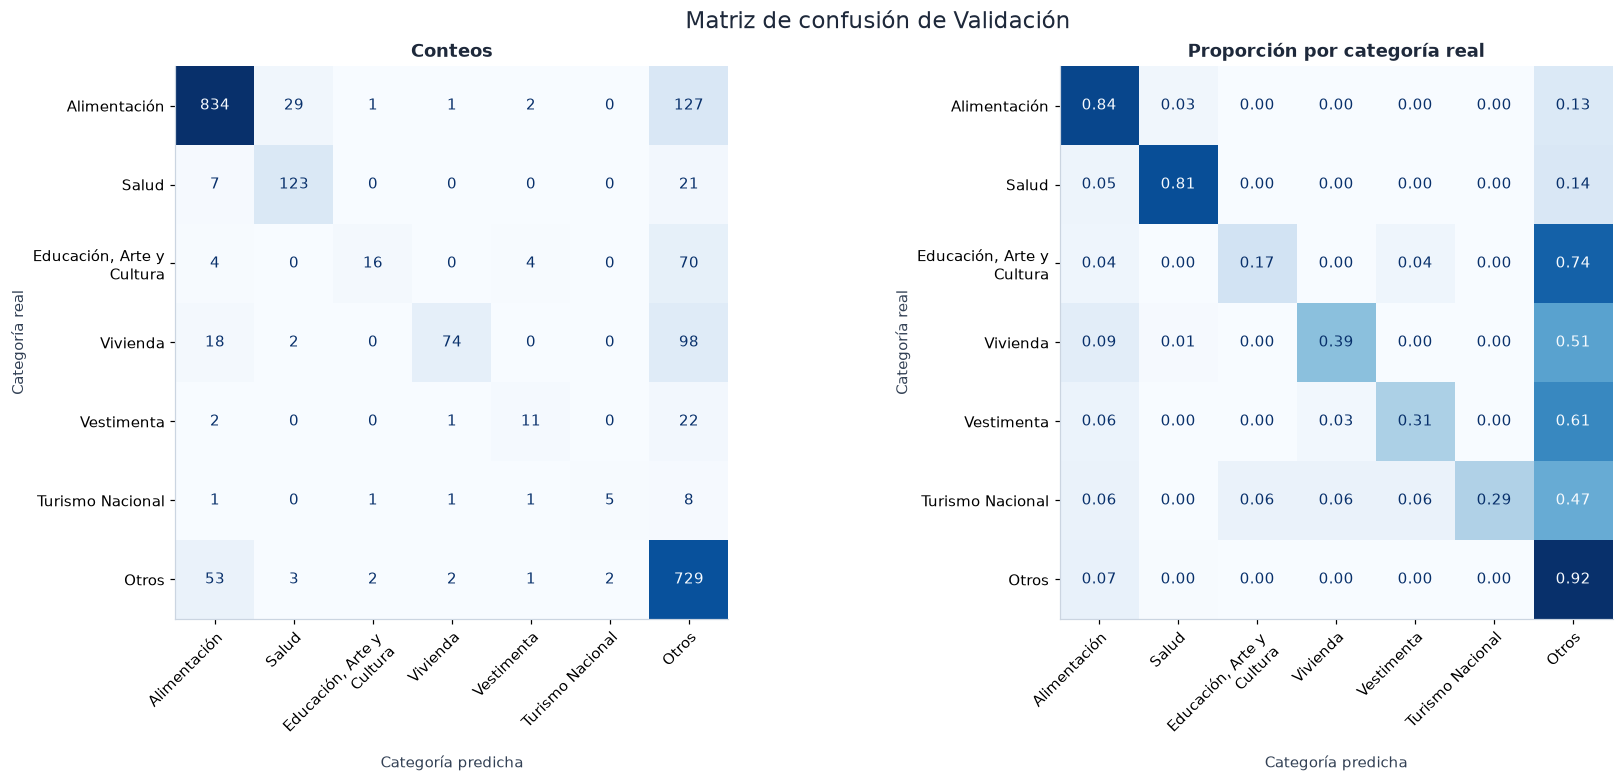

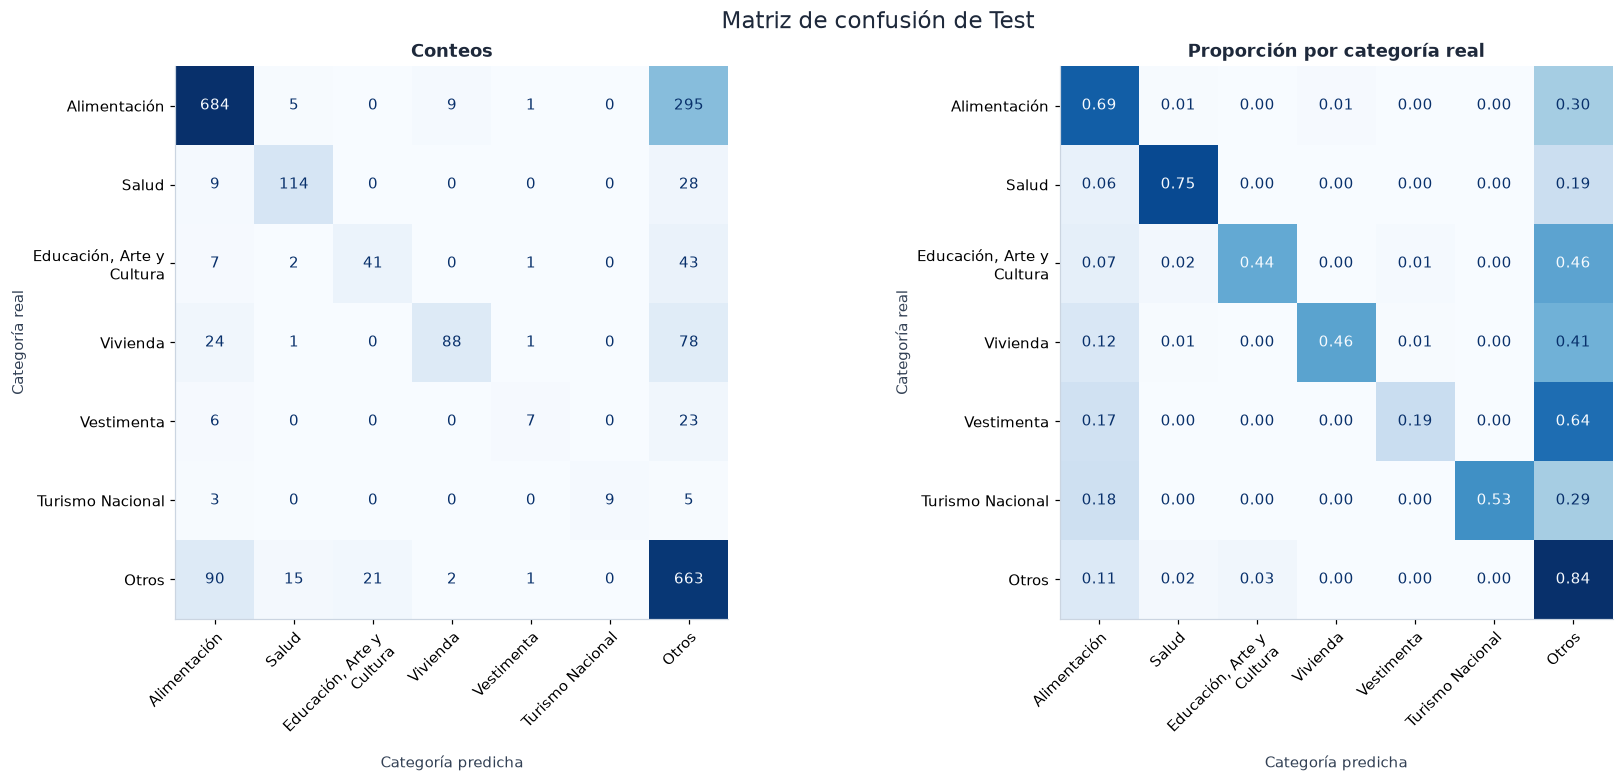

In [25]:
for figure_number, (partition, results) in enumerate(
    evaluation_results.items(), start=2
):
    figure, axes = plt.subplots(1, 2, figsize=(16, 7), layout="constrained")

    for axis, normalization, title in zip(
        axes, (None, "true"), ("Conteos", "Proporción por categoría real"), strict=True
    ):
        ConfusionMatrixDisplay.from_predictions(
            results["actual"],
            results["predicted"],
            labels=CATEGORIES,
            display_labels=category_tick_labels,
            normalize=normalization,
            values_format="d" if normalization is None else ".2f",
            cmap="Blues",
            colorbar=False,
            ax=axis,
        )
        axis.set_title(title)
        axis.set_xlabel("Categoría predicha")
        axis.set_ylabel("Categoría real")
        plt.setp(
            axis.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor"
        )

    figure.suptitle(f"Matriz de confusión de {PARTITION_NAMES[partition]}", fontsize=15)

    generate_and_save_figure(figure, f"{figure_number:02d}_confusion_{partition}")

### 4.3. Curvas ROC por categoría


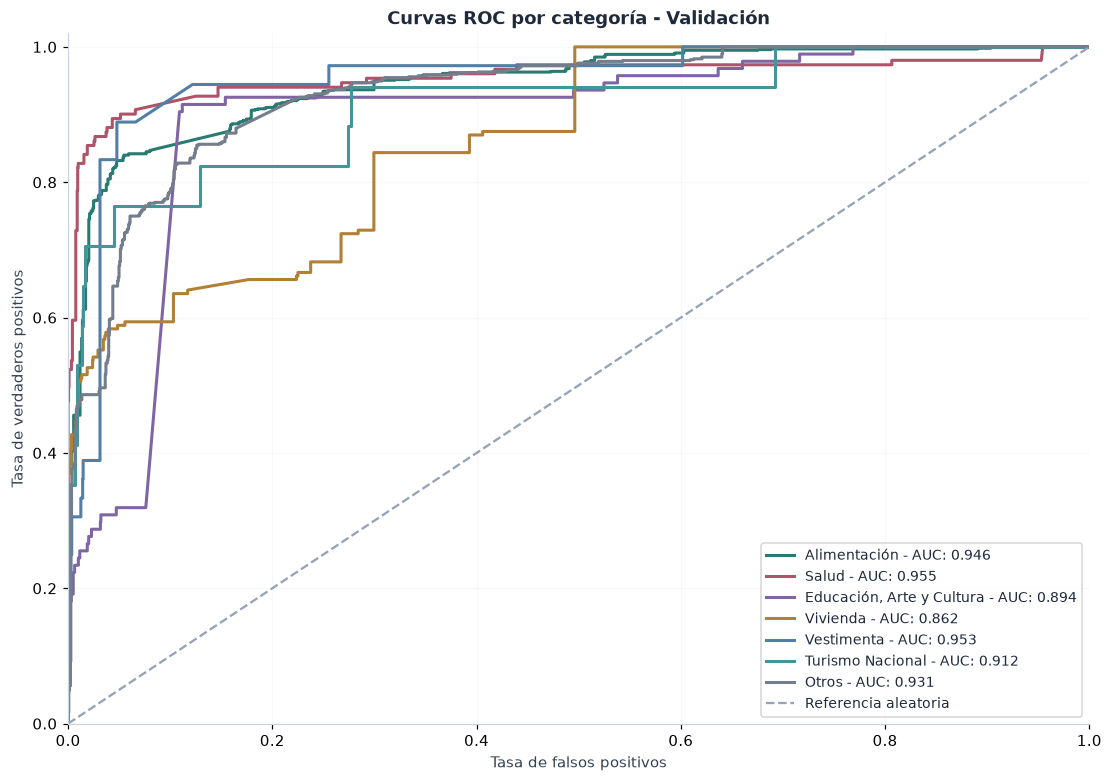

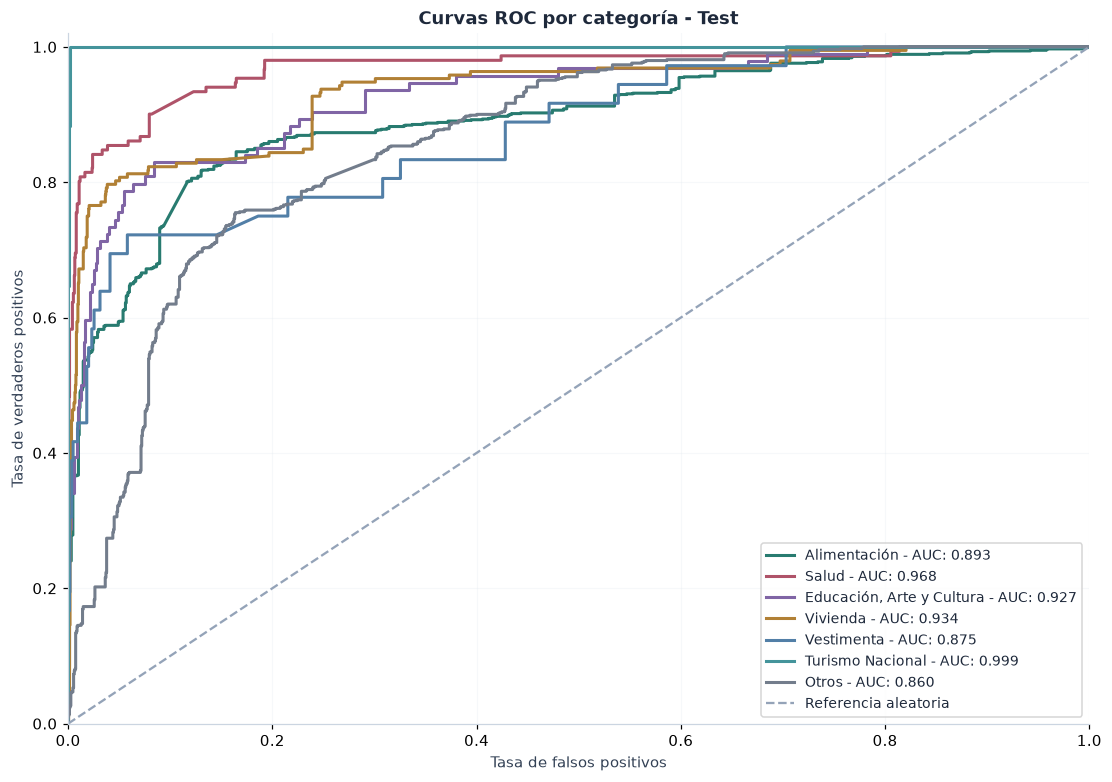

In [26]:
for figure_number, (partition, results) in enumerate(
    evaluation_results.items(), start=4
):
    figure, axis = plt.subplots(figsize=(10, 7), layout="constrained")

    for category in CATEGORIES:
        actual_members = results["actual"].eq(category).to_numpy()
        category_probabilities = results["probabilities"][:, class_columns[category]]
        false_positive_rates, true_positive_rates, _ = roc_curve(
            actual_members, category_probabilities
        )
        category_auc = roc_auc_score(actual_members, category_probabilities)

        axis.plot(
            false_positive_rates,
            true_positive_rates,
            color=category_colors[category],
            linewidth=2,
            label=f"{category} - AUC: {category_auc:.3f}",
        )

    axis.plot(
        [0, 1], [0, 1], linestyle="--", color="#94a3b8", label="Referencia aleatoria"
    )
    axis.set(
        xlim=(0, 1),
        ylim=(0, 1.02),
        xlabel="Tasa de falsos positivos",
        ylabel="Tasa de verdaderos positivos",
        title=f"Curvas ROC por categoría - {PARTITION_NAMES[partition]}",
    )
    axis.grid(alpha=0.3)
    axis.legend(loc="lower right", fontsize=9)

    generate_and_save_figure(figure, f"{figure_number:02d}_roc_{partition}")

## 5. Guardado


In [27]:
joblib.dump(model, MODELS_DIR / "concept_classifier.joblib")
metrics_by_partition.reset_index().to_parquet(
    REPORTS_DIR / "metrics.parquet", index=False
)

for partition, results in evaluation_results.items():
    report_text = classification_report(
        results["actual"],
        results["predicted"],
        labels=CATEGORIES,
        target_names=CATEGORIES,
        digits=4,
        zero_division=0,
    )
    (REPORTS_DIR / f"classification_report_{partition}.txt").write_text(
        report_text, encoding="utf-8"
    )

print("Modelo guardado exitosamente.")

Modelo guardado exitosamente.
